# 14 Fashion-MNIST MLP：rank 12での更新範囲ablation

Notebook 11で追加候補になったTT-rank 12について、`all_parameters`と`tt_cores_only`を同じepoch 0から比較します。

rank 12は、rank 16より強い圧縮でもaccuracyを回復できるか確認するための境界探索です。Notebook 13では更新方式の優劣がrankによって一貫しなかったため、このNotebookでも両方式を残します。

このNotebookは実装と検証までを扱います。結果の考察と一般化は別の会話で行います。

## 1. 実験で変えるものと固定するもの

比較する更新対象は次の2つです。

$$
\theta_{\mathrm{all}} = \{G_1,G_2,G_3,b_1,W_2,b_2,W_3,b_3\}
$$

$$
\theta_{\mathrm{TT}} = \{G_1,G_2,G_3\}
$$

両方式で、dense checkpoint、tensorization、requested rank、epoch 0のparameter値、seed、mini-batch順、optimizer、学習率、最大epoch数、early-stopping規則を揃えます。

- train 50,000件：fine-tuning
- early-stopping validation 5,000件：checkpoint選択
- rank-selection validation 5,000件：accuracy、agreement、logits RMSEの診断
- test 10,000件：予約のみ。このNotebookでは評価しない

epoch 0は3つ目の学習方式ではなく、両方式に共通する追加学習前の基準です。

In [11]:
# importとプロジェクトルートの解決
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import ast
import copy
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.compression import (
    TTLinear,
    factorize_named_tt_linear,
    tt_matrix_ranks,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    make_fashion_mnist_loaders,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import agreement, count_parameters, logits_rmse
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate, train_one_epoch
from nn_compression.utils import (
    find_project_root,
    get_experiment_dirs,
    make_torch_generator,
    set_seed,
)

In [12]:
# Notebook 13と同じ学習条件を固定する。
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
TARGET_LAYER = "fc1"
REQUESTED_RANK = 12
TRAIN_BATCH_SIZE = 64
VALIDATION_BATCH_SIZE = 64
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
PATIENCE = 5
MIN_DELTA = 1e-4
SAVE_RESULTS = True

set_seed(SEED)
project_root = find_project_root(Path.cwd())
data_dir, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "30_tt_mps",
    "10_fashion_mnist_mlp",
    "14_rank12_update_scope_ablation",
    create=False,
)
baseline_checkpoint_path = (
    project_root / "models" / "10_svd" / "20_fashion_mnist_mlp"
    / "03_mlp_svd_finetuning_using_src_corrected_rerun"
    / "baseline_same_run.pt"
)
selection_path = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "09_pretrained_mlp_fc1_tt_tensorization_comparison"
    / "selected_tensorizations.csv"
)
additional_rank_path = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "11_tt_rank_tradeoff_after_finetuning"
    / "additional_rank_requests.csv"
)
comparison13_path = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "13_tt_cores_only_ablation" / "update_scope_comparison.csv"
)

for required_path in [
    baseline_checkpoint_path, selection_path, additional_rank_path,
    comparison13_path,
]:
    if not required_path.is_file():
        raise FileNotFoundError(f"必要な入力がありません: {required_path}")

print("device:", DEVICE)
print("results target:", results_dir)

device: cuda
results target: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\14_rank12_update_scope_ablation


## 2. rank 12の由来とtensorizationを確認する

rank 12は結果を見て後付けした値ではなく、Notebook 11が保存した追加候補です。tensorizationはNotebook 09で3つの役割すべてに選ばれた`reversed_sites`を引き継ぎます。

rank 12には`aggressive`などの役割名を新しく付けません。Notebook 08で自動選択された3役割とは別の追加検証だからです。

In [13]:
df_selected09 = pd.read_csv(selection_path)
df_additional_rank = pd.read_csv(additional_rank_path)
df_reference13 = pd.read_csv(comparison13_path)

for column in ["out_modes", "in_modes", "actual_ranks"]:
    if column in df_selected09.columns:
        df_selected09[column] = df_selected09[column].map(
            lambda value: tuple(ast.literal_eval(value))
            if isinstance(value, str) else tuple(value)
        )

assert REQUESTED_RANK in set(df_additional_rank["requested_rank"].astype(int))
assert set(df_selected09["tensorization"]) == {"reversed_sites"}
assert df_selected09["out_modes"].nunique() == 1
assert df_selected09["in_modes"].nunique() == 1

reference_tensorization = df_selected09.iloc[0]
OUT_MODES = tuple(reference_tensorization["out_modes"])
IN_MODES = tuple(reference_tensorization["in_modes"])

rank12_request = df_additional_rank.loc[
    df_additional_rank["requested_rank"].astype(int) == REQUESTED_RANK
].copy()
assert len(rank12_request) == 1

display(rank12_request)
display(df_reference13[[
    "requested_rank", "update_scope", "selected_epoch",
    "rank_validation_accuracy", "prediction_agreement",
    "logits_rmse", "trainable_parameters",
]])
print("tensorization: reversed_sites")
print("out_modes:", OUT_MODES)
print("in_modes:", IN_MODES)

,requested_rank,between_rank_low,between_rank_high,reason
0,12,NaN,16,rank 16のfine-tuning後accuracyがdenseとの差の許容範囲内なので...


,requested_rank,update_scope,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,trainable_parameters
0,16,all_parameters,5,0.8890,0.9314,3.666437,153386
1,16,tt_cores_only,12,0.8904,0.9186,4.309767,18976
2,32,all_parameters,5,0.8850,0.9298,7.104990,205130
3,32,tt_cores_only,5,0.8926,0.9362,4.571566,70720
4,64,all_parameters,0,0.8872,0.9922,0.179470,406922
5,64,tt_cores_only,0,0.8872,0.9922,0.179470,272512


tensorization: reversed_sites
out_modes: (32, 8, 2)
in_modes: (2, 8, 49)


## 3. データ分割とdense baseline

Notebook 13と同じseed、分割、前処理を再構成します。`test_dataset_reserved`は長さだけを確認し、評価関数へ渡しません。

In [14]:
set_seed(SEED)
full_train_dataset, test_dataset_reserved = get_fashion_mnist_datasets(
    data_dir, download=False,
)
train_dataset, early_stopping_dataset, rank_validation_dataset = (
    split_fashion_mnist_dataset(
        full_train_dataset, (50_000, 5_000, 5_000), seed=SEED
    )
)
loaders = make_fashion_mnist_loaders(
    train_dataset,
    early_stopping_dataset,
    test_dataset_reserved,
    train_batch_size=TRAIN_BATCH_SIZE,
    validation_batch_size=VALIDATION_BATCH_SIZE,
    test_batch_size=1000,
    rank_validation_dataset=rank_validation_dataset,
    train_generator=make_torch_generator(SEED),
)
early_stopping_loader = loaders["validation_loader"]
rank_validation_loader = loaders["validation_loader_rank"]
criterion = torch.nn.CrossEntropyLoss()

baseline_state = torch.load(
    baseline_checkpoint_path, map_location=DEVICE, weights_only=True,
)
baseline_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
baseline_model.load_state_dict(baseline_state)
baseline_model.eval()
baseline_rank_loss, baseline_rank_accuracy = evaluate(
    baseline_model, rank_validation_loader, criterion, DEVICE,
)
baseline_parameters = count_parameters(baseline_model)

assert len(train_dataset) == 50_000
assert len(early_stopping_dataset) == 5_000
assert len(rank_validation_dataset) == 5_000
assert len(test_dataset_reserved) == 10_000
print(
    f"dense rank-validation: loss={baseline_rank_loss:.6f}, "
    f"accuracy={baseline_rank_accuracy:.4f}"
)
print("test set: reserved and not evaluated")

dense rank-validation: loss=0.310588, accuracy=0.8884
test set: reserved and not evaluated


## 4. TODO実装契約

TODOは順番に実装し、1つ終えるたびに入力、出力、禁止事項を照合します。

### TODO 1：rank 12の共通epoch 0と2更新方式を準備する

- 入力：`baseline_state`、`OUT_MODES`、`IN_MODES`、`REQUESTED_RANK`
- 行うこと：dense checkpointからrank 12のTTモデルを1つ作り、deep copyで2方式へ分ける
- 行わないこと：loader使用、forward評価、学習、checkpoint保存
- 出力：`candidate_models[update_scope]`、`optimizers[update_scope]`、`initial_parameter_states[update_scope]`、TT構造と更新対象の記録
- 完了条件：2モデルの全parameter値が完全一致し、違うのは`requires_grad`とoptimizerの対象だけ

### TODO 2：同一条件で2 trialを学習する

- 入力：TODO 1の辞書、3つのdataset／loader、`baseline_model`
- 行うこと：trialごとに同じseedのnew train loaderを作り、epoch 0をinitial bestとして学習する
- 行わないこと：rank-validation指標による選択や停止、test評価、途中の条件変更
- 出力：`epoch0_records`、`history_records`、`selected_records`、`selected_models[update_scope]`
- 完了条件：2 trialが同じearly-stopping規則で選択済みstateへ復元される

### TODO 3：固定parameterとTT構造を検証する

- 入力：選択済みモデル、学習前parameter、初期core shape、initial actual rank
- 行うこと：学習前後の完全一致、最大変化量、core shape、actual rankを検証する
- 行わないこと：再学習、評価指標の再計算
- 出力：`parameter_verification_records`
- 完了条件：`tt_cores_only`の固定parameterがすべて完全一致し、TT構造が不変

### TODO 4〜6：表、図、保存

recordから表を作り、epoch 0と選択済み状態を区別して可視化します。test評価、結果を見た学習条件変更、Notebook 13成果物の上書きは行いません。

## TODO 1：rank 12のepoch 0モデルを準備する

### このセルで確認すること

学習済みdenseモデルの`fc1`を3-core TTLinearへ置き換えます。requested rank 12と、実際に生成されたbond dimensionを混同しないでください。

### 実装方針

1. 新しい`MNISTMLP`へ`baseline_state`を読み込む。
2. `factorize_named_tt_linear`で`fc1`だけをTT化する。
3. `TTLinear`、`tt_matrix_ranks`、core shape、総parameter数を確認する。
4. 共通epoch 0をdeep copyし、2つの独立したモデルを作る。
5. `all_parameters`では全parameter、`tt_cores_only`では`fc1.cores.*`だけを学習可能にする。
6. optimizerには学習可能parameterだけを渡す。
7. 両方式の全parameter値が完全一致することを確認する。

既存の`TTLinear`、`factorize_named_tt_linear`、`tt_matrix_ranks`、`count_parameters`を使い、同じ機能を作り直さないでください。

In [15]:
# TODO 1: rank 12の共通epoch 0から2つの更新方式を準備する。
# 上の7段階を順に実装し、ここでは学習や評価を行わない。

update_scopes = ("all_parameters", "tt_cores_only")
candidate_models = {}
optimizers = {}
initial_parameter_states = {}
trainable_parameter_records = []
initial_core_shapes = {}
initial_actual_ranks = {}

set_seed(SEED)

# 1. 学習済み重みを読み込むためのdenseモデルを作る。
epoch0_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)

# 2. 全層を同じ学習済みdense checkpointの値にする。
epoch0_model.load_state_dict(baseline_state)

# 3. fc1だけをTTLinearへ置き換える。
epoch0_model = factorize_named_tt_linear(
    epoch0_model,
    TARGET_LAYER,
    out_modes=OUT_MODES,
    in_modes=IN_MODES ,
    max_rank=REQUESTED_RANK,
)

# 4. fc1がTTLinearへ置換されたことを確認する。
assert isinstance(epoch0_model.fc1, TTLinear)

# 生成されたTT構造を取得する。
actual_ranks = tt_matrix_ranks(
    list(epoch0_model.fc1.cores)
)

core_shapes = tuple(
    tuple(core.shape)
    for core in epoch0_model.fc1.cores
)

print("actual_ranks:", actual_ranks)
print("core_shapes:", core_shapes)

# 共通epoch 0から、独立した2モデルを作る。
models_for_scope = {
    "all_parameters": copy.deepcopy(epoch0_model),
    "tt_cores_only": copy.deepcopy(epoch0_model),
}

# tt_cores_onlyで学習対象となるparameter名。
expected_core_names = {
    "fc1.cores.0",
    "fc1.cores.1",
    "fc1.cores.2",
}

for update_scope, model in models_for_scope.items():

    # まず全parameterを固定する。
    for parameter in model.parameters():
        parameter.requires_grad_(False)

    # 方式に応じて、必要なparameterだけ学習可能にする。
    if update_scope == "all_parameters":
        for parameter in model.parameters():
            parameter.requires_grad_(True)
    else:
        for name, parameter in model.named_parameters():
            is_core = name.startswith("fc1.cores.")
            parameter.requires_grad_(is_core)

    # 学習可能なparameterの名前を取り出す。
    trainable_names = {
        name
        for name, parameter in model.named_parameters()
        if parameter.requires_grad
    }

    # 更新対象が意図どおりであることを確認する。
    if update_scope == "all_parameters":
        assert trainable_names == {
            name for name, _ in model.named_parameters()
        }
    else:
        assert trainable_names == expected_core_names 

    print(update_scope, sorted(trainable_names))

    # 学習対象の名前とparameterを組にして取り出す。
    trainable_named_parameters = [
        (name, parameter)
        for name, parameter in model.named_parameters()
        if parameter.requires_grad
    ]

    # Adamへ渡すのは名前ではなくparameter本体。
    trainable_parameters = [
        parameter
        for _, parameter in trainable_named_parameters
    ]

    # 学習対象の総要素数。
    trainable_parameter_count = sum(
        parameter.numel()
        for parameter in trainable_parameters
    )

    # 各方式で独立したoptimizerを作る。
    optimizer = torch.optim.Adam(
        trainable_parameters,
        lr=LEARNING_RATE,
    )

    # 後の学習セルで使うモデルとoptimizer。
    candidate_models[update_scope] = models_for_scope[update_scope]
    optimizers[update_scope] = optimizer

    # 固定parameterも含めて、全parameterの学習前の値を保存する。
    initial_parameter_states[update_scope] = {
        name: parameter.detach().clone()
        for name, parameter in model.named_parameters()
    }

    # 学習前のTT構造を保存する。
    initial_core_shapes[update_scope] = tuple(
        tuple(core.shape)
        for core in model.fc1.cores
    )
    initial_actual_ranks[update_scope] = tt_matrix_ranks(
        list(model.fc1.cores)
    )

    print(
        update_scope,
        "trainable:", trainable_parameter_count,
        "total:", count_parameters(model),
    )
        # 【配置A】
    # 外側のfor update_scope, model ...の内側。
    # 前の問題の最後のprint(...)の直後に追加する。

    for name, parameter in trainable_named_parameters:
        trainable_parameter_records.append({
            "requested_rank": REQUESTED_RANK,
            "update_scope":update_scope,
            "parameter_name": name,
            "numel": parameter.numel(),
            "trainable_parameters": trainable_parameter_count,
        })

    # コピー後も、共通epoch 0と同じTT構造であることを確認。
    assert initial_core_shapes[update_scope] == core_shapes
    assert initial_actual_ranks[update_scope] == actual_ranks
    assert count_parameters(model) == count_parameters(epoch0_model)


# 【配置B】
# 外側のforループがすべて終了した後。
# ここからはインデントなしで追加する。

assert set(candidate_models) == set(update_scopes)
assert set(optimizers) == set(update_scopes)
assert set(initial_parameter_states) == set(update_scopes)

# 2方式で、parameter名の集合が一致することを確認。
assert (
    initial_parameter_states["all_parameters"].keys()
    == initial_parameter_states["tt_cores_only"].keys()
)

# 全parameterについて、初期値が完全一致することを確認。
for name in initial_parameter_states["all_parameters"]:
    assert torch.equal(
        initial_parameter_states["all_parameters"][name],
        initial_parameter_states["tt_cores_only"][name],
    ), f"epoch 0 mismatch: {name}"

# TT構造も両方式で一致することを確認。
assert (
    initial_core_shapes["all_parameters"]
    == initial_core_shapes["tt_cores_only"]
)
assert (
    initial_actual_ranks["all_parameters"]
    == initial_actual_ranks["tt_cores_only"]
)

print("TODO 1: two untrained epoch-0 models are ready")

# Adamの対象が、学習可能なparameterと一致するか確認する。
for update_scope, optimizer in optimizers.items():
    model = candidate_models[update_scope]

    expected_ids = {
        id(parameter)
        for parameter in model.parameters()
        if parameter.requires_grad
    }

    actual_ids = {
        id(parameter)
        for group in optimizer.param_groups
        for parameter in group["params"]
    }

    assert actual_ids == expected_ids, update_scope


# 更新対象の記録を表示する。ここからは点検用ループの外。
df_trainable_parameter_setup = pd.DataFrame(
    trainable_parameter_records
)

display(
    df_trainable_parameter_setup[
        ["update_scope", "parameter_name", "numel"]
    ]
)

# 個別parameterの要素数を合計し、方式ごとの学習対象数を表示する。
display(
    df_trainable_parameter_setup.groupby(
        "update_scope",
        as_index=False,
    )["numel"].sum()
)

print("actual_ranks:", actual_ranks)
print("core_shapes:", core_shapes)
print("total parameters:", count_parameters(epoch0_model))

actual_ranks: (1, 12, 12, 1)
core_shapes: ((1, 32, 2, 12), (12, 8, 8, 12), (12, 2, 49, 1))
all_parameters ['fc1.bias', 'fc1.cores.0', 'fc1.cores.1', 'fc1.cores.2', 'fc2.bias', 'fc2.weight', 'fc3.bias', 'fc3.weight']
all_parameters trainable: 145570 total: 145570
tt_cores_only ['fc1.cores.0', 'fc1.cores.1', 'fc1.cores.2']
tt_cores_only trainable: 11160 total: 145570
TODO 1: two untrained epoch-0 models are ready


,update_scope,parameter_name,numel
0,all_parameters,fc1.bias,512
1,all_parameters,fc1.cores.0,768
2,all_parameters,fc1.cores.1,9216
3,all_parameters,fc1.cores.2,1176
4,all_parameters,fc2.weight,131072
5,all_parameters,fc2.bias,256
6,all_parameters,fc3.weight,2560
7,all_parameters,fc3.bias,10
8,tt_cores_only,fc1.cores.0,768
9,tt_cores_only,fc1.cores.1,9216


,update_scope,numel
0,all_parameters,145570
1,tt_cores_only,11160


actual_ranks: (1, 12, 12, 1)
core_shapes: ((1, 32, 2, 12), (12, 8, 8, 12), (12, 2, 49, 1))
total parameters: 145570


## TODO 2：epoch 0を含めて2 trialを学習する

### checkpoint選択

epoch 0のearly-stopping validation lossを最初のbestとします。epoch $t$のlossを$L_t$、現在のbestを$L_{\mathrm{best}}$とすると、更新条件は

$$
L_{\mathrm{best}} - L_t > \delta, \qquad \delta=10^{-4}
$$

です。判定後の`best_updated`と`patience_counter`を各epochの履歴へ保存します。

### 実装方針

- trialごとに`set_seed(SEED)`を呼び、`make_torch_generator(SEED)`を渡したnew train loaderを作る。
- epoch 0と各epochでearly-stopping validationを評価する。
- rank-validation accuracy、agreement、logits RMSEは診断として記録するだけにする。
- best判定とpatience更新の後に履歴を追加する。
- 学習後は必ずbest stateへ戻し、選択済み指標を再評価する。
- epoch 0と選択済み状態を別recordに残し、追加学習の変化を後で計算できるようにする。

`train_one_epoch`、`evaluate`、`agreement`、`logits_rmse`を再利用してください。

In [16]:
# TODO 2: rank 12 × 2更新方式を同一条件で学習する。
# TODO 1を再実行せず、このセルだけを再実行してはいけない。
epoch0_records = []
history_records = []
selected_records = []
selected_models = {}

# TODO: epoch 0評価、学習、early stopping、best state復元を実装する。
# rank-validation指標とtest setを選択判断に使わないこと。
# ============================================================
# A. trialごとのモデル・optimizer・loader準備
# ============================================================
for update_scope in update_scopes:
    model = candidate_models[update_scope]
    optimizer = optimizers[update_scope]

    set_seed(SEED)

    trial_loaders = make_fashion_mnist_loaders(
        train_dataset,
        early_stopping_dataset,
        test_dataset_reserved,
        train_batch_size=TRAIN_BATCH_SIZE,
        validation_batch_size=VALIDATION_BATCH_SIZE,
        test_batch_size=1000,
        rank_validation_dataset=rank_validation_dataset,
        train_generator=make_torch_generator(SEED),
    )

    train_loader = trial_loaders["train_loader"]
    early_stopping_loader = trial_loaders["validation_loader"]
    rank_validation_loader = trial_loaders["validation_loader_rank"]

    model_parameters = count_parameters(model)
    trainable_parameter_count = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    # ========================================================
    # B. epoch 0を評価し、最初のbestとして保存
    # ========================================================
    validation_loss, validation_accuracy = evaluate(
        model,
        early_stopping_loader,
        criterion,
        DEVICE,
    )

    best_loss = validation_loss
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    patience_counter = 0
    cumulative_training_seconds = 0.0

    # rank-validationは診断用。best判定には使わない。
    rank_validation_loss, rank_validation_accuracy = evaluate(
        model,
        rank_validation_loader,
        criterion,
        DEVICE,
    )

    prediction_agreement = agreement(
        baseline_model,
        model,
        rank_validation_loader,
        DEVICE,
    )

    logits_error = logits_rmse(
        baseline_model,
        model,
        rank_validation_loader,
        DEVICE,
    )

    # 追加学習前の状態を独立したrecordとして残す。
    epoch0_records.append({
        "requested_rank": REQUESTED_RANK,
        "update_scope": update_scope,
        "epoch": 0,
        "actual_ranks": initial_actual_ranks[update_scope],
        "core_shapes": initial_core_shapes[update_scope],
        "model_parameters": model_parameters,
        "model_compression_ratio":count_parameters(baseline_model)/ model_parameters,
        "trainable_parameters": trainable_parameter_count,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
        "rank_validation_loss": rank_validation_loss,
        "rank_validation_accuracy": rank_validation_accuracy,
        "prediction_agreement": prediction_agreement,
        "logits_rmse": logits_error,
    })

    # 学習履歴にもepoch 0を含める。
    # epoch 0では学習していないのでtrain指標はNaN。
    history_records.append({
        "requested_rank": REQUESTED_RANK,
        "update_scope": update_scope,
        "epoch": 0,
        "train_loss": float("nan"),
        "train_accuracy": float("nan"),
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
        "rank_validation_loss": rank_validation_loss,
        "rank_validation_accuracy": rank_validation_accuracy,
        "prediction_agreement": prediction_agreement,
        "logits_rmse": logits_error,
        "cumulative_training_seconds": cumulative_training_seconds,
        "best_updated": True,
        "patience_counter": patience_counter,
    })

    # ========================================================
    # C. epoch 1以降の学習
    # ========================================================
    for epoch in range(1, MAX_EPOCHS + 1):
        training_start = time.perf_counter()

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            DEVICE,
        )

        cumulative_training_seconds += (
            time.perf_counter() - training_start
        )

        # checkpoint選択に使う評価。
        validation_loss, validation_accuracy = evaluate(
            model,
            early_stopping_loader,
            criterion,
            DEVICE,
        )

        # 診断用の評価。
        rank_validation_loss, rank_validation_accuracy = evaluate(
            model,
            rank_validation_loader,
            criterion,
            DEVICE,
        )

        prediction_agreement = agreement(
            baseline_model,
            model,
            rank_validation_loader,
            DEVICE,
        )

        logits_error = logits_rmse(
            baseline_model,
            model,
            rank_validation_loader,
            DEVICE,
        )

        # ====================================================
        # D. bestとpatienceを更新
        # ====================================================
        if best_loss - validation_loss > MIN_DELTA:
            best_updated = True
            best_loss = validation_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            best_updated = False
            patience_counter += 1

        # 判定後のbest_updated・patience_counterを記録する。
        history_records.append({
            "requested_rank": REQUESTED_RANK,
            "update_scope": update_scope,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "rank_validation_loss": rank_validation_loss,
            "rank_validation_accuracy": rank_validation_accuracy,
            "prediction_agreement": prediction_agreement,
            "logits_rmse": logits_error,
            "cumulative_training_seconds": cumulative_training_seconds,
            "best_updated": best_updated,
            "patience_counter": patience_counter,
        })

        print(
            f"{update_scope} | epoch={epoch:02d} | "
            f"validation_loss={validation_loss:.6f} | "
            f"best_epoch={best_epoch} | "
            f"patience={patience_counter}"
        )

        # 停止するepochも記録してからbreakする。
        if patience_counter >= PATIENCE:
            break

    # ========================================================
    # E. epochループ終了後、best stateへ復元
    # この部分はtrialループ内・epochループ外。
    # ========================================================
    model.load_state_dict(best_state)

    selected_validation_loss, selected_validation_accuracy = evaluate(
        model,
        early_stopping_loader,
        criterion,
        DEVICE,
    )

    selected_rank_loss, selected_rank_accuracy = evaluate(
        model,
        rank_validation_loader,
        criterion,
        DEVICE,
    )

    selected_agreement = agreement(
        baseline_model,
        model,
        rank_validation_loader,
        DEVICE,
    )

    selected_rmse = logits_rmse(
        baseline_model,
        model,
        rank_validation_loader,
        DEVICE,
    )

    selected_records.append({
        "requested_rank": REQUESTED_RANK,
        "update_scope": update_scope,
        "selected_epoch": best_epoch,
        "actual_ranks": initial_actual_ranks[update_scope],
        "core_shapes": initial_core_shapes[update_scope],
        "validation_loss": selected_validation_loss,
        "validation_accuracy": selected_validation_accuracy,
        "rank_validation_loss": selected_rank_loss,
        "rank_validation_accuracy": selected_rank_accuracy,
        "prediction_agreement": selected_agreement,
        "logits_rmse": selected_rmse,
        "model_parameters": model_parameters,
        "model_compression_ratio": baseline_parameters / model_parameters,
        "trainable_parameters": trainable_parameter_count,
        "cumulative_training_seconds": cumulative_training_seconds,
        "num_epochs_run": epoch,
    })

    selected_models[update_scope] = model

    print(
        f"{update_scope} selected: epoch={best_epoch}, "
        f"validation_loss={selected_validation_loss:.6f}, "
        f"rank_accuracy={selected_rank_accuracy:.4f}"
    )


# ============================================================
# F. 両trial終了後の確認：すべてのループの外
# ============================================================
assert len(epoch0_records) == 2
assert len(selected_records) == 2
assert set(selected_models) == set(update_scopes)

for update_scope in update_scopes:
    trial_history = [
        record
        for record in history_records
        if record["update_scope"] == update_scope
    ]
    assert trial_history[0]["epoch"] == 0

print("TODO 2: two trials completed and best states restored")


all_parameters | epoch=01 | validation_loss=0.380804 | best_epoch=1 | patience=0
all_parameters | epoch=02 | validation_loss=0.370241 | best_epoch=2 | patience=0
all_parameters | epoch=03 | validation_loss=0.357431 | best_epoch=3 | patience=0
all_parameters | epoch=04 | validation_loss=0.325811 | best_epoch=4 | patience=0
all_parameters | epoch=05 | validation_loss=0.322348 | best_epoch=5 | patience=0
all_parameters | epoch=06 | validation_loss=0.314003 | best_epoch=6 | patience=0
all_parameters | epoch=07 | validation_loss=0.305487 | best_epoch=7 | patience=0
all_parameters | epoch=08 | validation_loss=0.312241 | best_epoch=7 | patience=1
all_parameters | epoch=09 | validation_loss=0.317740 | best_epoch=7 | patience=2
all_parameters | epoch=10 | validation_loss=0.316578 | best_epoch=7 | patience=3
all_parameters | epoch=11 | validation_loss=0.334093 | best_epoch=7 | patience=4
all_parameters | epoch=12 | validation_loss=0.312736 | best_epoch=7 | patience=5
all_parameters selected: epo

## TODO 3：固定parameterとTT構造を検証する

### このセルで確認すること

`tt_cores_only`で固定した`fc1.bias`、`fc2`、`fc3`が学習前と完全一致することを確認します。また、学習によってTT coreのshapeやbond dimensionが変わっていないことを確認します。

### 実装方針

1. `selected_models[update_scope]`と`initial_parameter_states[update_scope]`を対応させる。
2. named parameterごとに`torch.equal`と最大絶対変化量を計算する。
3. `requires_grad=False`のparameterは完全一致をassertする。
4. `tt_matrix_ranks`とcore shapeが学習前後で同じことをassertする。
5. parameter名、学習対象か、要素数、完全一致、最大変化量をrecordへ保存する。

In [17]:
# TODO 3: 学習前後のparameter値とTT構造を検証する。
# このセルでは再学習や評価指標の再計算を行わない。
parameter_verification_records = []

selected_epoch_by_scope = {
    record["update_scope"]: record["selected_epoch"]
    for record in selected_records
}

for update_scope in update_scopes:
    model = selected_models[update_scope]
    initial_parameters = initial_parameter_states[update_scope]

    assert isinstance(model.fc1, TTLinear)

    current_core_shapes = tuple(
        tuple(core.shape) for core in model.fc1.cores
    )
    current_actual_ranks = tt_matrix_ranks(list(model.fc1.cores))

    assert current_core_shapes == initial_core_shapes[update_scope]
    assert current_actual_ranks == initial_actual_ranks[update_scope]
    assert count_parameters(model) == count_parameters(
        candidate_models[update_scope]
    )

    for name, parameter in model.named_parameters():
        initial_parameter = initial_parameters[name]
        current_parameter = parameter.detach()
        assert current_parameter.shape == initial_parameter.shape

        exact_equal = torch.equal(current_parameter, initial_parameter)
        max_abs_change = (
            current_parameter - initial_parameter
        ).abs().max().item()

        if not parameter.requires_grad:
            assert exact_equal, (
                f"Frozen parameter changed: {update_scope}, {name}"
            )

        parameter_verification_records.append({
            "requested_rank": REQUESTED_RANK,
            "update_scope": update_scope,
            "parameter_name": name,
            "is_trainable": bool(parameter.requires_grad),
            "numel": parameter.numel(),
            "exact_equal": exact_equal,
            "max_abs_change": max_abs_change,
            "selected_epoch": selected_epoch_by_scope[update_scope],
        })

recorded_scopes = {
    record["update_scope"] for record in parameter_verification_records
}
assert recorded_scopes == set(update_scopes)

expected_record_count = sum(
    len(list(model.named_parameters()))
    for model in selected_models.values()
)
assert len(parameter_verification_records) == expected_record_count

assert all(
    record["exact_equal"]
    for record in parameter_verification_records
    if not record["is_trainable"]
)

print("TODO 3: frozen parameters and TT structure verified")


TODO 3: frozen parameters and TT structure verified


## TODO 4：比較用DataFrameを作る

次の5表をlong形式で作ります。

- `df_rank12_epoch0`：両方式に共通する追加学習前指標
- `df_rank12_comparison`：2方式の選択済み結果とepoch 0からの変化
- `df_rank12_history`：epoch 0を含む学習履歴
- `df_rank12_trainable_parameters`：更新対象名と要素数
- `df_rank12_parameter_verification`：学習前後のparameter検証

accuracy、agreement、logits RMSEは異なる量です。差分列も指標ごとに分け、混ぜて合成スコアにしません。

In [18]:
# TODO 4: TODO 1〜3のrecordから次の5つのDataFrameを作る。
# モデルの再評価、条件選択、可視化は行わない。

scope_order = ["all_parameters", "tt_cores_only"]

df_rank12_epoch0 = (
    pd.DataFrame(epoch0_records)
    .assign(
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        )
    )
    .sort_values("update_scope")
    .reset_index(drop=True)
)

df_selected_stage = (
    pd.DataFrame(selected_records)
    .assign(
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        )
    )
    .sort_values("update_scope")
    .reset_index(drop=True)
)

# epoch 0 と選択後を並べ、変化量を計算する
df_rank12_comparison = df_selected_stage.merge(
    df_rank12_epoch0[
        [
            "update_scope",
            "rank_validation_accuracy",
            "prediction_agreement",
            "logits_rmse",
            "validation_loss",
            "validation_accuracy",
        ]
    ].rename(
        columns={
            "rank_validation_accuracy": "rank_validation_accuracy_epoch0",
            "prediction_agreement": "prediction_agreement_epoch0",
            "logits_rmse": "logits_rmse_epoch0",
            "validation_loss": "validation_loss_epoch0",
            "validation_accuracy": "validation_accuracy_epoch0",
        }
    ),
    on="update_scope",
    validate="one_to_one",
)
df_rank12_comparison["accuracy_change_from_epoch0"] = (
    df_rank12_comparison["rank_validation_accuracy"]
    - df_rank12_comparison["rank_validation_accuracy_epoch0"]
)
df_rank12_comparison["agreement_change_from_epoch0"] = (
    df_rank12_comparison["prediction_agreement"]
    - df_rank12_comparison["prediction_agreement_epoch0"]
)
df_rank12_comparison["logits_rmse_change_from_epoch0"] = (
    df_rank12_comparison["logits_rmse"]
    - df_rank12_comparison["logits_rmse_epoch0"]
)

df_rank12_history = (
    pd.DataFrame(history_records)
    .assign(
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        )
    )
    .sort_values(["update_scope", "epoch"])
    .reset_index(drop=True)
)

df_rank12_trainable_parameters = (
    pd.DataFrame(trainable_parameter_records)[
        [
            "requested_rank",
            "update_scope",
            "parameter_name",
            "numel",
        ]
    ]
    .assign(
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        )
    )
    .sort_values(["update_scope", "parameter_name"])
    .reset_index(drop=True)
)

df_rank12_parameter_verification = (
    pd.DataFrame(parameter_verification_records)
    .assign(
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        )
    )
    .sort_values(["update_scope", "parameter_name"])
    .reset_index(drop=True)
)

assert len(df_rank12_epoch0) == 2
assert len(df_rank12_comparison) == 2
assert set(df_rank12_comparison["update_scope"].astype(str)) == set(scope_order)
assert df_rank12_comparison["update_scope"].is_unique
assert (
    df_rank12_history.groupby("update_scope", observed=True)["epoch"].min() == 0
).all()
assert df_rank12_comparison["rank_validation_accuracy"].between(0.0, 1.0).all()
assert df_rank12_comparison["prediction_agreement"].between(0.0, 1.0).all()
assert (df_rank12_comparison["logits_rmse"] >= 0.0).all()
assert (
    df_rank12_parameter_verification.loc[
        ~df_rank12_parameter_verification["is_trainable"],
        "exact_equal",
    ].all()
)

display(df_rank12_epoch0.round(6))
display(df_rank12_comparison.round(6))
display(df_rank12_history.head(12))
display(
    df_rank12_trainable_parameters.groupby(
        "update_scope", observed=True, as_index=False
    )["numel"].sum()
)
display(df_rank12_parameter_verification.head(12))


,requested_rank,update_scope,epoch,actual_ranks,core_shapes,model_parameters,model_compression_ratio,trainable_parameters,validation_loss,validation_accuracy,rank_validation_loss,rank_validation_accuracy,prediction_agreement,logits_rmse
0,12,all_parameters,0,"(1, 12, 12, 1)","((1, 32, 2, 12), (12, 8, 8, 12), (12, 2, 49, 1))",145570,3.680827,145570,1.669115,0.3982,1.659271,0.395,0.4092,8.442084
1,12,tt_cores_only,0,"(1, 12, 12, 1)","((1, 32, 2, 12), (12, 8, 8, 12), (12, 2, 49, 1))",145570,3.680827,11160,1.669115,0.3982,1.659271,0.395,0.4092,8.442084


,requested_rank,update_scope,selected_epoch,actual_ranks,core_shapes,validation_loss,validation_accuracy,rank_validation_loss,rank_validation_accuracy,prediction_agreement,...,cumulative_training_seconds,num_epochs_run,rank_validation_accuracy_epoch0,prediction_agreement_epoch0,logits_rmse_epoch0,validation_loss_epoch0,validation_accuracy_epoch0,accuracy_change_from_epoch0,agreement_change_from_epoch0,logits_rmse_change_from_epoch0
0,12,all_parameters,7,"(1, 12, 12, 1)","((1, 32, 2, 12), (12, 8, 8, 12), (12, 2, 49, 1))",0.305487,0.8846,0.327022,0.8848,0.9304,...,43.254342,12,0.395,0.4092,8.442084,1.669115,0.3982,0.4898,0.5212,-4.041940
1,12,tt_cores_only,17,"(1, 12, 12, 1)","((1, 32, 2, 12), (12, 8, 8, 12), (12, 2, 49, 1))",0.310498,0.8846,0.312643,0.8884,0.9280,...,72.294720,22,0.395,0.4092,8.442084,1.669115,0.3982,0.4934,0.5188,-3.344765


,requested_rank,update_scope,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,rank_validation_loss,rank_validation_accuracy,prediction_agreement,logits_rmse,cumulative_training_seconds,best_updated,patience_counter
0,12,all_parameters,0,NaN,NaN,1.669115,0.3982,1.659271,0.3950,0.4092,8.442084,0.000000,True,0
1,12,all_parameters,1,0.430330,0.83912,0.380804,0.8530,0.393952,0.8528,0.8908,3.652097,3.573182,True,0
2,12,all_parameters,2,0.349529,0.86972,0.370241,0.8586,0.367708,0.8620,0.8832,2.904560,6.934446,True,0
3,12,all_parameters,3,0.321512,0.87922,0.357431,0.8612,0.352591,0.8636,0.9022,3.043522,10.711839,True,0
4,12,all_parameters,4,0.298583,0.88682,0.325811,0.8804,0.332512,0.8786,0.9198,2.832086,14.403308,True,0
5,12,all_parameters,5,0.281835,0.89328,0.322348,0.8778,0.322252,0.8846,0.9252,3.319978,18.412530,True,0
6,12,all_parameters,6,0.268444,0.89748,0.314003,0.8868,0.320299,0.8848,0.9128,3.812755,22.236783,True,0
7,12,all_parameters,7,0.254823,0.90204,0.305487,0.8846,0.327022,0.8848,0.9304,4.400143,25.934189,True,0
8,12,all_parameters,8,0.244145,0.90736,0.312241,0.8890,0.331426,0.8888,0.9122,5.752714,29.484164,False,1
9,12,all_parameters,9,0.232276,0.91058,0.317740,0.8814,0.323908,0.8882,0.9252,6.155182,32.871970,False,2


,update_scope,numel
0,all_parameters,145570
1,tt_cores_only,11160


,requested_rank,update_scope,parameter_name,is_trainable,numel,exact_equal,max_abs_change,selected_epoch
0,12,all_parameters,fc1.bias,True,512,False,0.304311,7
1,12,all_parameters,fc1.cores.0,True,768,False,0.180667,7
2,12,all_parameters,fc1.cores.1,True,9216,False,0.500369,7
3,12,all_parameters,fc1.cores.2,True,1176,False,0.536430,7
4,12,all_parameters,fc2.bias,True,256,False,0.174685,7
5,12,all_parameters,fc2.weight,True,131072,False,0.642596,7
6,12,all_parameters,fc3.bias,True,10,False,0.118630,7
7,12,all_parameters,fc3.weight,True,2560,False,0.877783,7
8,12,tt_cores_only,fc1.bias,False,512,True,0.000000,17
9,12,tt_cores_only,fc1.cores.0,True,768,False,0.369277,17


## TODO 5：可視化する

matplotlibで次を別々に描きます。

1. epoch 0と選択済みrank-validation accuracy
2. epoch 0と選択済みprediction agreement
3. epoch 0と選択済みlogits RMSE
4. 更新方式ごとのtrainable parameter数
5. early-stopping validation lossの学習曲線

accuracyの図だけにdense baselineを表示します。agreementとaccuracyは同じ軸へ重ねません。rankは12だけなので、rankを連続軸にした折れ線グラフにはしません。

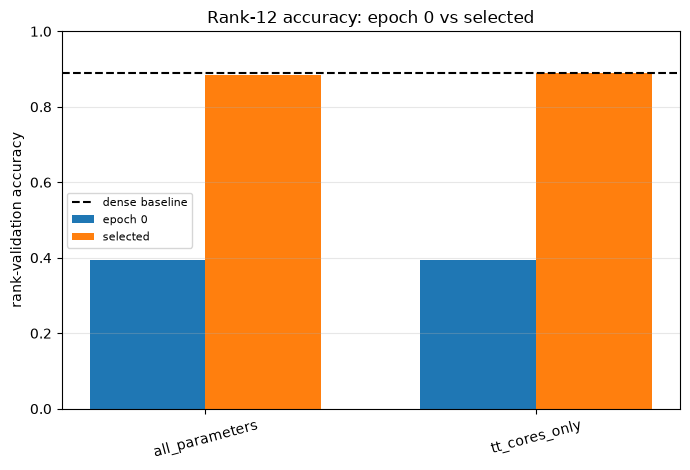

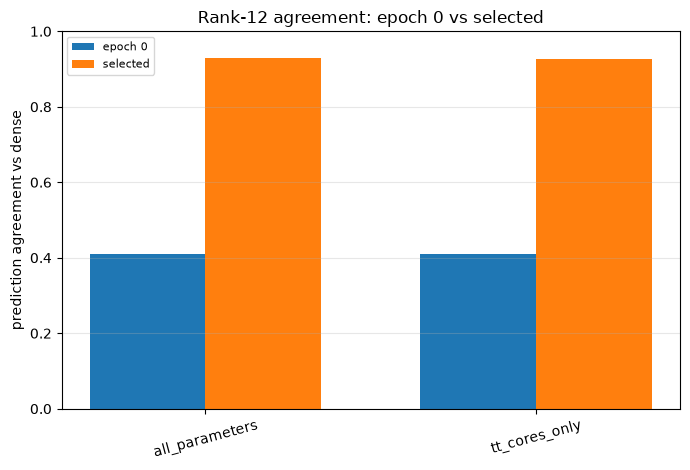

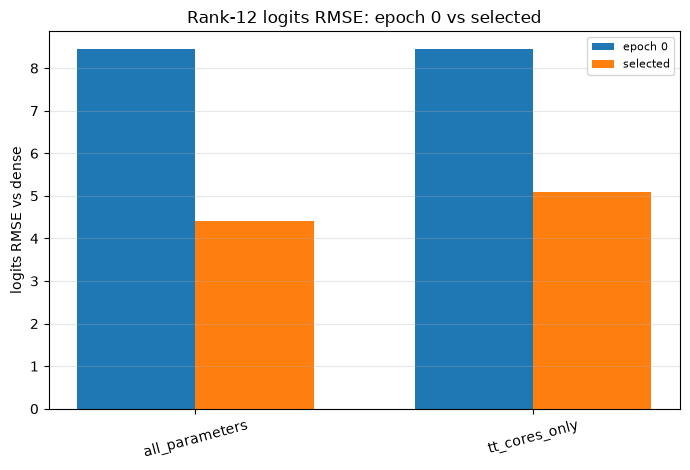

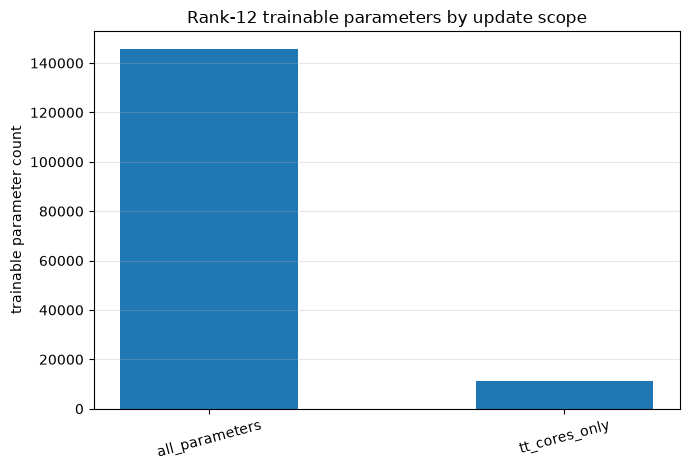

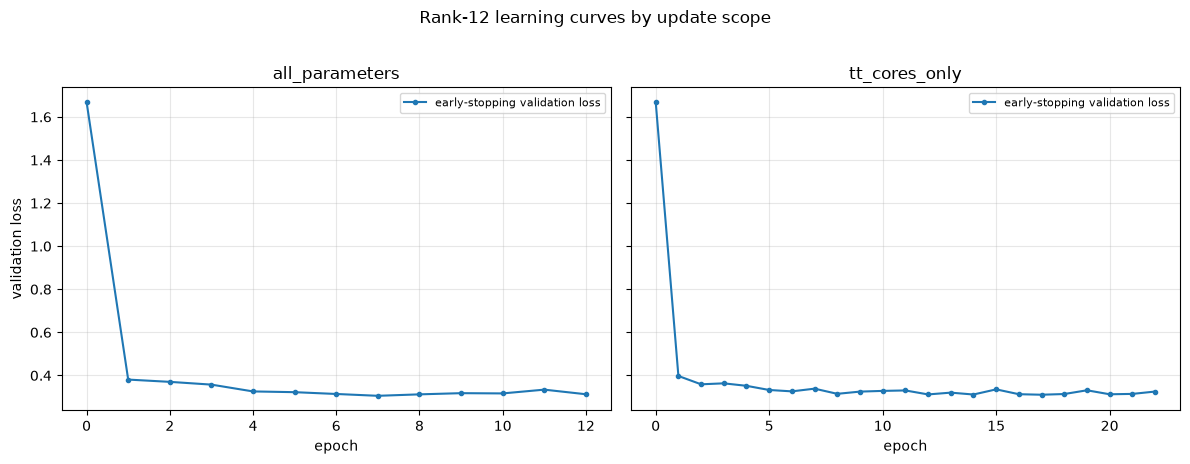

In [19]:
# TODO 5: TODO 4のDataFrameだけを描画元にする。
# Figureは保存セルへ渡せるよう、次の変数名へ格納する。

scopes = ["all_parameters", "tt_cores_only"]
x = range(len(scopes))
width = 0.35


def _values(frame, column):
    return [
        float(frame.loc[frame["update_scope"] == scope, column].iloc[0])
        for scope in scopes
    ]


# 1) epoch 0 / selected rank-validation accuracy + dense baseline
fig_accuracy, ax_acc = plt.subplots(figsize=(7.0, 4.8))
epoch0_acc = _values(df_rank12_epoch0, "rank_validation_accuracy")
selected_acc = _values(df_rank12_comparison, "rank_validation_accuracy")
ax_acc.bar(
    [position - width / 2 for position in x],
    epoch0_acc,
    width=width,
    label="epoch 0",
)
ax_acc.bar(
    [position + width / 2 for position in x],
    selected_acc,
    width=width,
    label="selected",
)
ax_acc.axhline(
    baseline_rank_accuracy,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="dense baseline",
)
ax_acc.set_xticks(list(x), scopes, rotation=15)
ax_acc.set_ylim(0.0, 1.0)
ax_acc.set_ylabel("rank-validation accuracy")
ax_acc.set_title("Rank-12 accuracy: epoch 0 vs selected")
ax_acc.grid(True, axis="y", alpha=0.3)
ax_acc.legend(fontsize=8)
fig_accuracy.tight_layout()
plt.show()

# 2) prediction agreement（accuracyとは別図）
fig_agreement, ax_agr = plt.subplots(figsize=(7.0, 4.8))
epoch0_agr = _values(df_rank12_epoch0, "prediction_agreement")
selected_agr = _values(df_rank12_comparison, "prediction_agreement")
ax_agr.bar(
    [position - width / 2 for position in x],
    epoch0_agr,
    width=width,
    label="epoch 0",
)
ax_agr.bar(
    [position + width / 2 for position in x],
    selected_agr,
    width=width,
    label="selected",
)
ax_agr.set_xticks(list(x), scopes, rotation=15)
ax_agr.set_ylim(0.0, 1.0)
ax_agr.set_ylabel("prediction agreement vs dense")
ax_agr.set_title("Rank-12 agreement: epoch 0 vs selected")
ax_agr.grid(True, axis="y", alpha=0.3)
ax_agr.legend(fontsize=8)
fig_agreement.tight_layout()
plt.show()

# 3) logits RMSE
fig_logits_rmse, ax_rmse = plt.subplots(figsize=(7.0, 4.8))
epoch0_rmse = _values(df_rank12_epoch0, "logits_rmse")
selected_rmse = _values(df_rank12_comparison, "logits_rmse")
ax_rmse.bar(
    [position - width / 2 for position in x],
    epoch0_rmse,
    width=width,
    label="epoch 0",
)
ax_rmse.bar(
    [position + width / 2 for position in x],
    selected_rmse,
    width=width,
    label="selected",
)
ax_rmse.set_xticks(list(x), scopes, rotation=15)
ax_rmse.set_ylabel("logits RMSE vs dense")
ax_rmse.set_title("Rank-12 logits RMSE: epoch 0 vs selected")
ax_rmse.grid(True, axis="y", alpha=0.3)
ax_rmse.legend(fontsize=8)
fig_logits_rmse.tight_layout()
plt.show()

# 4) trainable parameter count
fig_trainable_parameters, ax_tp = plt.subplots(figsize=(7.0, 4.8))
trainable_counts = _values(df_rank12_comparison, "trainable_parameters")
ax_tp.bar(list(x), trainable_counts, width=0.5)
ax_tp.set_xticks(list(x), scopes, rotation=15)
ax_tp.set_ylabel("trainable parameter count")
ax_tp.set_title("Rank-12 trainable parameters by update scope")
ax_tp.grid(True, axis="y", alpha=0.3)
fig_trainable_parameters.tight_layout()
plt.show()

# 5) learning curves
fig_learning_curves, axes_lc = plt.subplots(
    1, 2, figsize=(12, 4.5), sharey=True
)
for ax, scope in zip(axes_lc, scopes):
    history = (
        df_rank12_history.loc[df_rank12_history["update_scope"] == scope]
        .sort_values("epoch")
    )
    ax.plot(
        history["epoch"],
        history["validation_loss"],
        marker="o",
        markersize=3,
        label="early-stopping validation loss",
    )
    ax.set_xlabel("epoch")
    ax.set_title(f"{scope}")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes_lc[0].set_ylabel("validation loss")
fig_learning_curves.suptitle(
    "Rank-12 learning curves by update scope",
    y=1.02,
)
fig_learning_curves.tight_layout()
plt.show()

assert fig_accuracy is not None
assert fig_agreement is not None
assert fig_logits_rmse is not None
assert fig_trainable_parameters is not None
assert fig_learning_curves is not None
assert fig_accuracy is not fig_agreement


## TODO 6：Notebook 14専用成果物を保存する

`SAVE_RESULTS=True`のときだけ、Notebook 14専用ディレクトリへ5 CSV、5 Figure、2 checkpointを保存します。Notebook 13の成果物は上書きも複製もしません。保存セルでは再学習・再評価を行いません。

In [20]:
# TODO 6: 表、Figure、選択済みstate_dictだけを保存する。
# results_dirとmodels_dirは保存直前に作る。
# test評価や既存成果物の上書きは行わない。

if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)

    def prepare_csv_frame(frame):
        out = frame.copy()
        for column in out.columns:
            if str(out[column].dtype) == "category":
                out[column] = out[column].astype(str)
            elif out[column].map(lambda value: isinstance(value, tuple)).any():
                out[column] = out[column].map(str)
        return out

    path_epoch0 = results_dir / "rank12_epoch0.csv"
    path_comparison = results_dir / "rank12_comparison.csv"
    path_history = results_dir / "rank12_history.csv"
    path_trainable = results_dir / "rank12_trainable_parameters.csv"
    path_verification = results_dir / "rank12_parameter_verification.csv"

    path_fig_accuracy = results_dir / "rank12_accuracy.png"
    path_fig_agreement = results_dir / "rank12_agreement.png"
    path_fig_rmse = results_dir / "rank12_logits_rmse.png"
    path_fig_trainable = results_dir / "rank12_trainable_parameters.png"
    path_fig_curves = results_dir / "rank12_learning_curves.png"

    prepare_csv_frame(df_rank12_epoch0).to_csv(path_epoch0, index=False)
    prepare_csv_frame(df_rank12_comparison).to_csv(path_comparison, index=False)
    prepare_csv_frame(df_rank12_history).to_csv(path_history, index=False)
    prepare_csv_frame(df_rank12_trainable_parameters).to_csv(
        path_trainable, index=False
    )
    prepare_csv_frame(df_rank12_parameter_verification).to_csv(
        path_verification, index=False
    )

    fig_accuracy.savefig(path_fig_accuracy, dpi=150, bbox_inches="tight")
    fig_agreement.savefig(path_fig_agreement, dpi=150, bbox_inches="tight")
    fig_logits_rmse.savefig(path_fig_rmse, dpi=150, bbox_inches="tight")
    fig_trainable_parameters.savefig(
        path_fig_trainable, dpi=150, bbox_inches="tight"
    )
    fig_learning_curves.savefig(path_fig_curves, dpi=150, bbox_inches="tight")

    checkpoint_paths = []
    for update_scope, model in selected_models.items():
        checkpoint_path = models_dir / f"{update_scope}_selected.pt"
        torch.save(model.state_dict(), checkpoint_path)
        checkpoint_paths.append(checkpoint_path)
        print("saved checkpoint:", checkpoint_path.name)

    saved_paths = [
        path_epoch0,
        path_comparison,
        path_history,
        path_trainable,
        path_verification,
        path_fig_accuracy,
        path_fig_agreement,
        path_fig_rmse,
        path_fig_trainable,
        path_fig_curves,
        *checkpoint_paths,
    ]
    for path_item in saved_paths:
        assert path_item.is_file(), path_item

    # Notebook 13 の成果物は変更していない
    assert comparison13_path.is_file()

    assert len(checkpoint_paths) == 2
    print("saved tables/figures to:", results_dir)
    print("saved checkpoints to:", models_dir)
else:
    print("SAVE_RESULTS=False: 結果は保存していません。")


saved checkpoint: all_parameters_selected.pt
saved checkpoint: tt_cores_only_selected.pt
saved tables/figures to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\14_rank12_update_scope_ablation
saved checkpoints to: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\10_fashion_mnist_mlp\14_rank12_update_scope_ablation


## 5. 実装後のチェックリスト

- [ ] rank 12がNotebook 11の保存済み追加候補から取得されている
- [ ] tensorizationがNotebook 09の`reversed_sites`と一致する
- [ ] 2方式が完全に同じepoch 0 parameterから始まる
- [ ] trialごとに同じseedのnew train loaderを作る
- [ ] epoch 0がbest候補とpatience軌跡へ含まれる
- [ ] checkpoint選択にearly-stopping validation lossだけを使う
- [ ] rank-validation指標を選択・停止・条件変更に使わない
- [ ] `tt_cores_only`の固定parameterが完全一致する
- [ ] actual rankとcore shapeが学習前後で不変である
- [ ] accuracyとagreementを別図にする
- [ ] test setを評価していない
- [ ] Notebook 13の成果物を変更していない

結果を確認した後も、この1 seedだけから更新方式の一般的優劣を断定しません。追加の学習率探索や複数seedは、rank 12の結果から必要性を判断して別Notebookへ分けます。